# 02 — Data Preprocessing et GroupSplit (HAM10000)

**Objectif :** créer des ensembles Train, Validation et Test **sans lésions partagées**, vérifier la distribution des sept classes et calculer les **Class Weights uniquement sur Train**.

- Dataset : HAM10000, **10 015 images**, **7 classes** et **7 470 lésions uniques**.
- Méthode : `GroupShuffleSplit` sur `lesion_id`, cible **70 / 15 / 15**.
- Modèles concernés : ResNet50, EfficientNet-B0 et ViT (Fine-Tuning ImageNet).

> Les résultats de ce notebook sont les partitions fixes du projet. Les modèles doivent tous réutiliser les mêmes CSV. 

## 1. Bibliothèques et chemins

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Graine aléatoire pour la reproductibilité
SEED = 42
np.random.seed(SEED)

# Chemin du dataset HAM10000
DATA_DIR = Path(
    "/kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000"
)

# Dossier contenant les images
IMAGES_DIR = DATA_DIR / "images"

# Dossier pour sauvegarder les résultats du prétraitement
OUTPUT_DIR = Path("/kaggle/working/ham10000_Portfolio")

# Dossier pour les partitions Train, Validation et Test
SPLITS_DIR = OUTPUT_DIR / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset :", DATA_DIR)
print("Images :", IMAGES_DIR)
print("Partitions :", SPLITS_DIR)

Dataset : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000
Images : /kaggle/input/datasets/imaneelqoraychy/ham-dataset/HAM10000/images
Partitions : /kaggle/working/ham10000_Portfolio/splits


## 2. Chargement et contrôles de qualité

In [2]:
# 1. Vérifier la présence du dataset
metadata_path = DATA_DIR / "HAM10000_metadata.csv"

if not metadata_path.exists():
    raise FileNotFoundError("Fichier metadata introuvable.")

if not IMAGES_DIR.is_dir():
    raise FileNotFoundError("Dossier images introuvable.")


# 2. Charger les métadonnées
df = pd.read_csv(metadata_path)


# 3. Vérifier les colonnes obligatoires
required_columns = ["image_id", "lesion_id", "dx"]

if not set(required_columns).issubset(df.columns):
    raise ValueError("Certaines colonnes obligatoires sont absentes.")


# 4. Vérifier les valeurs manquantes
if df[required_columns].isnull().any().any():
    raise ValueError("Valeurs manquantes dans les colonnes obligatoires.")


# 5. Vérifier les doublons d'identifiants
if df["image_id"].duplicated().any():
    raise ValueError("Des image_id sont dupliqués.")


# 6. Récupérer les fichiers images
image_files = [
    path for path in IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Vérifier les images avec des identifiants identiques
image_ids = [path.stem for path in image_files]

if len(image_ids) != len(set(image_ids)):
    raise ValueError("Des images possèdent le même identifiant.")


# 7. Associer les images aux métadonnées
image_paths = {
    path.stem: str(path) for path in image_files
}

df["image_path"] = df["image_id"].map(image_paths)

if df["image_path"].isnull().any():
    raise FileNotFoundError("Certaines images sont manquantes.")


# 8. Vérifier les 7 classes
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

if set(df["dx"].unique()) != set(CLASSES):
    raise ValueError("Les classes du dataset sont incorrectes.")


# 9. Encoder les classes en nombres
class_to_idx = {
    classe: i for i, classe in enumerate(CLASSES)
}

df["label"] = df["dx"].map(class_to_idx).astype(int)


# 10. Afficher le résumé
print("Nombre d'images :", len(df))
print("Images indexées :", len(image_files))
print("Nombre de classes :", df["dx"].nunique())
print("Lésions uniques :", df["lesion_id"].nunique())
print("Images manquantes :", df["image_path"].isnull().sum())

if len(df) != 10015:
    print("Attention : 10 015 images attendues.")

print("\nEncodage des classes :")
print(class_to_idx)

display(df.head())

Nombre d'images : 10015
Images indexées : 10015
Nombre de classes : 7
Lésions uniques : 7470
Images manquantes : 0

Encodage des classes :
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/imaneelqoraychy/ham-dat...,2


### Vérification du chargement

Les contrôles exécutés ont confirmé : **10 015 images**, **7 classes**, **7 470 lésions** et **0 image manquante**. L'ordre des labels est : `akiec=0`, `bcc=1`, `bkl=2`, `df=3`, `mel=4`, `nv=5`, `vasc=6`.

La présence de plusieurs images d'une même lésion justifie une séparation au niveau de `lesion_id`. Elle ne garantit pas une séparation au niveau des patients, puisque `patient_id` n'est pas disponible ici.

## 3. GroupSplit : Train 70 %, Validation 15 %, Test 15 %

In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Proportions souhaitées
TARGET = {"train": 0.70, "val": 0.15, "test": 0.15}

# Nombre de séparations à tester
N_CANDIDATES = 120

# Distribution des classes dans le dataset complet
class_distribution = df["dx"].value_counts(normalize=True)

best_score = float("inf")
best_parts = None
selected_seed = None


# 1. Tester plusieurs séparations reproductibles
for seed in range(SEED, SEED + N_CANDIDATES):

    # Première séparation : 70 % Train / 30 % restant
    splitter = GroupShuffleSplit(
        n_splits=1,
        train_size=0.70,
        random_state=seed
    )

    train_idx, temp_idx = next(
        splitter.split(df, groups=df["lesion_id"])
    )

    train = df.iloc[train_idx].copy()
    temp = df.iloc[temp_idx].copy()


    # Deuxième séparation : diviser le restant en deux
    splitter = GroupShuffleSplit(
        n_splits=1,
        train_size=0.50,
        random_state=seed + 10000
    )

    val_idx, test_idx = next(
        splitter.split(temp, groups=temp["lesion_id"])
    )

    val = temp.iloc[val_idx].copy()
    test = temp.iloc[test_idx].copy()

    parts = {"train": train, "val": val, "test": test}


    # 2. Vérifier la présence des 7 classes
    if any(set(part["dx"]) != set(CLASSES)
           for part in parts.values()):
        continue


    # 3. Mesurer l'écart par rapport aux proportions souhaitées
    size_error = sum(
        abs(len(part) / len(df) - TARGET[name])
        for name, part in parts.items()
    )


    # 4. Mesurer le déséquilibre des classes entre les partitions
    class_error = 0

    for part in parts.values():
        distribution = part["dx"].value_counts(normalize=True)
        difference = (
            distribution.reindex(CLASSES, fill_value=0)
            - class_distribution.reindex(CLASSES, fill_value=0)
        )
        class_error += difference.abs().mean()


    # 5. Conserver la meilleure séparation
    score = size_error + class_error

    if score < best_score:
        best_score = score
        best_parts = parts
        selected_seed = seed


# Vérifier qu'une séparation valide a été trouvée
if best_parts is None:
    raise ValueError("Aucune séparation valide trouvée.")

parts = best_parts


# 6. Vérifier l'absence de Data Leakage
train_ids = set(parts["train"]["lesion_id"])
val_ids = set(parts["val"]["lesion_id"])
test_ids = set(parts["test"]["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)


# 7. Vérifier que toutes les images ont été réparties
assert sum(len(part) for part in parts.values()) == len(df)

all_images = pd.concat(parts.values())["image_id"]

assert all_images.is_unique
assert set(all_images) == set(df["image_id"])


# 8. Afficher les résultats
print("Graine sélectionnée :", selected_seed)

for name, part in parts.items():
    print(
        f"{name} : {len(part)} images "
        f"({len(part) / len(df):.2%}), "
        f"{part['lesion_id'].nunique()} lésions"
    )

print("\nAucune lésion partagée : OK")
print("Toutes les images réparties : OK")

Graine sélectionnée : 71
train : 7012 images (70.01%), 5229 lésions
val : 1501 images (14.99%), 1120 lésions
test : 1502 images (15.00%), 1121 lésions

Aucune lésion partagée : OK
Toutes les images réparties : OK


### Résultats observés et interprétation

| Ensemble | Images | Part des images | Lésions uniques |
|---|---:|---:|---:|
| Train | 7 012 | 70,01 % | 5 229 |
| Validation | 1 501 | 14,99 % | 1 120 |
| Test | 1 502 | 15,00 % | 1 121 |

La graine retenue est **71**. Les contrôles confirment **aucun `lesion_id` partagé** et **aucune image perdue ou dupliquée** entre les ensembles. Nous conserverons exactement ces partitions pendant tout le projet.

## 4. Distribution des classes après séparation

Nombre d'images par classe :


,train,val,test
dx,,,
akiec,228,43,56
bcc,381,73,60
bkl,743,167,189
df,75,24,16
mel,783,176,154
nv,4701,998,1006
vasc,101,20,21
TOTAL,7012,1501,1502


Répartition des classes (%) :


,train,val,test
dx,,,
akiec,69.72,13.15,17.13
bcc,74.12,14.20,11.67
bkl,67.61,15.20,17.20
df,65.22,20.87,13.91
mel,70.35,15.81,13.84
nv,70.11,14.88,15.00
vasc,71.13,14.08,14.79


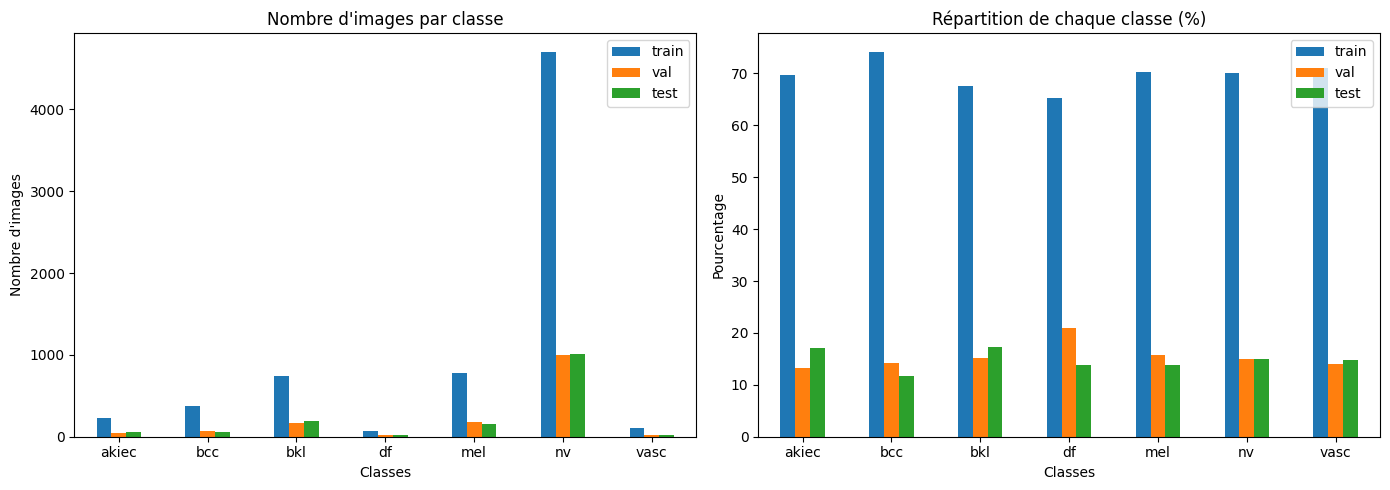

Vérification des classes terminée.


In [4]:
# 1. Compter les images par classe dans chaque ensemble
class_counts = pd.DataFrame({
    name: part["dx"].value_counts().reindex(CLASSES, fill_value=0)
    for name, part in parts.items()
})

# Ajouter les totaux
class_counts.loc["TOTAL"] = class_counts.sum()

print("Nombre d'images par classe :")
display(class_counts)


# 2. Calculer la répartition de chaque classe (%)
class_percentages = class_counts.drop("TOTAL")

class_percentages = (
    class_percentages
    .div(class_percentages.sum(axis=1), axis=0)
    * 100
)

print("Répartition des classes (%) :")
display(class_percentages.round(2))


# 3. Visualiser les résultats
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Nombre d'images par classe
class_counts.drop("TOTAL").plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Nombre d'images par classe")
axes[0].set_xlabel("Classes")
axes[0].set_ylabel("Nombre d'images")
axes[0].tick_params(axis="x", rotation=0)


# Graphique 2 : Répartition des classes en %
class_percentages.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Répartition de chaque classe (%)")
axes[1].set_xlabel("Classes")
axes[1].set_ylabel("Pourcentage")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()


# 4. Sauvegarder les graphiques
plt.savefig(
    SPLITS_DIR / "split_class_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# 5. Vérifier que les 7 classes sont présentes
for name, part in parts.items():

    assert part["dx"].nunique() == 7, (
        f"Classe manquante dans {name}"
    )

    # Vérifier les proportions 70/15/15
    ratio = len(part) / len(df)

    if abs(ratio - TARGET[name]) > 0.025:
        print(f"Attention : proportion incorrecte dans {name}")

print("Vérification des classes terminée.")

- Les **sept classes sont présentes** dans les trois ensembles. La classe `nv` demeure majoritaire : **4 701** images en Train, tandis que `df` ne compte que **75** images en Train (**16** en Test). Le mélanome (`mel`) compte **783** images en Train, **176** en Validation et **154** en Test.

- Les écarts entre classes sont acceptables au regard de l'isolation des lésions, mais les classes rares demandent une attention particulière : métriques **macro-F1**, **recall par classe** et intervalles d'incertitude si possible.

## 5. Sauvegarde et relecture des trois partitions

In [5]:
# 1. Sauvegarder les trois partitions
for name, part in parts.items():

    # Exclure les chemins absolus des images
    data_to_save = part.drop(columns=["image_path"])

    # Chemin du fichier CSV
    file_path = SPLITS_DIR / f"{name}.csv"

    # Enregistrer les données
    data_to_save.sort_values("image_id").to_csv(
        file_path,
        index=False
    )

    print(f"{name}.csv enregistré : {len(part)} images")


# 2. Recharger les fichiers pour les vérifier
train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "val.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")


# 3. Vérifier l'absence de lésions communes
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

assert train_lesions.isdisjoint(val_lesions)
assert train_lesions.isdisjoint(test_lesions)
assert val_lesions.isdisjoint(test_lesions)


# 4. Vérifier que toutes les images sont présentes
all_images = pd.concat([train_df, val_df, test_df])

assert len(all_images) == len(df)
assert all_images["image_id"].is_unique
assert set(all_images["image_id"]) == set(df["image_id"])


# 5. Afficher la confirmation
print("\nTous les fichiers CSV ont été vérifiés.")
print("Aucune lésion commune. ")
print("Toutes les images présentes.")

train.csv enregistré : 7012 images
val.csv enregistré : 1501 images
test.csv enregistré : 1502 images

Tous les fichiers CSV ont été vérifiés.
Aucune lésion commune. 
Toutes les images présentes.


## 6. Calcul des Class Weights — Train uniquement

HAM10000 est fortement déséquilibré : la classe `nv` domine, alors que `df` et `vasc` sont rares. Pour la future perte pondérée, nous calculons un poids par classe **sur les 7 012 images d’entraînement uniquement** :

$$
w_c = \frac{N_{\mathrm{train}}}{K \times N_c}
$$

- `N_train` : nombre d’images de Train , `K = 7` : nombre de classes , `N_c` : nombre d’images de la classe `c` dans Train.
- Les classes rares reçoivent des poids plus grands.
- **Validation et Test ne participent jamais au calcul**, afin d’éviter toute fuite d’information.

Ce calcul ne garantit pas une amélioration des résultats : nous comparerons les métriques de validation.

In [6]:
# 1. Compter les images de chaque classe dans Train
train_counts = train_df["label"].value_counts().reindex(range(len(CLASSES)), fill_value=0)

# Toutes les classes doivent être présentes dans Train
assert (train_counts > 0).all(), "Au moins une classe absente de Train."

# 2. Calculer les poids équilibrés uniquement sur Train
class_weights = len(train_df) / (len(CLASSES) * train_counts)

# 3. Afficher les effectifs et les poids dans l'ordre des labels
weights_table = pd.DataFrame({
    "Classe": CLASSES,
    "Label": range(len(CLASSES)),
    "Images Train": train_counts.values,
    "Poids": class_weights.values.round(4)
})

display(weights_table)

# Dictionnaire sauvegardable en JSON, dans le même ordre de classes
weights_by_class = {
    classe: float(class_weights.iloc[i])
    for i, classe in enumerate(CLASSES)
}


,Classe,Label,Images Train,Poids
0,akiec,0,228,4.3935
1,bcc,1,381,2.6292
2,bkl,2,743,1.3482
3,df,3,75,13.3562
4,mel,4,783,1.2793
5,nv,5,4701,0.2131
6,vasc,6,101,9.9180


- Les classes rares (`df`, `vasc`) reçoivent des poids plus élevés que la classe majoritaire (`nv`). Une erreur sur une classe rare contribuera donc davantage à la perte d'entraînement. Les poids sont **des coefficients de la loss**, pas des duplications d'images.

## 7. Sauvegarde de `data_config.json`

In [7]:
# Sauvegarder la configuration qui sera utilisée dans 03_ModelsTraining.ipynb
config = {
    "classes": CLASSES,
    "class_to_idx": class_to_idx,
    "seed_split_selected": int(selected_seed),
    "target_split_ratios": TARGET,
    "split_sizes": {name: len(part) for name, part in parts.items()},
    "class_counts_train_only": {
        classe: int(train_counts.iloc[i]) for i, classe in enumerate(CLASSES)
    },
    "class_weights_train_only": weights_by_class
}

config_path = OUTPUT_DIR / "data_config.json"
with open(config_path, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4, ensure_ascii=False)

print("Configuration enregistrée :", config_path)
print("Splits enregistrés dans :", SPLITS_DIR)

# Vérifier le fichier en le rechargeant
with open(config_path, encoding="utf-8") as file:
    saved_config = json.load(file)

assert saved_config["classes"] == CLASSES
assert saved_config["seed_split_selected"] == selected_seed
print("Vérification de la configuration : OK")


Configuration enregistrée : /kaggle/working/ham10000_Portfolio/data_config.json
Splits enregistrés dans : /kaggle/working/ham10000_Portfolio/splits
Vérification de la configuration : OK


## 8. Conclusion et livrables

Le prétraitement a produit trois partitions de tailles très proches de **70/15/15**, sans chevauchement de lésions (`lesion_id`) : **7 012 / 1 501 / 1 502 images**. Toutes les classes sont représentées dans chaque ensemble. Les poids équilibrés sont calculés **uniquement sur Train**.

**Livrables attendus dans Kaggle :**
- `ham10000_Portfolio/splits/train.csv`
- `ham10000_Portfolio/splits/val.csv`
- `ham10000_Portfolio/splits/test.csv`
- `ham10000_Portfolio/splits/split_class_distribution.png`
- `ham10000_Portfolio/data_config.json`
